# Fig. 5g: weights of the model of good units (spontaneous regime)

**author**: laquitainesteeve@gmail.com

**purpose**: weights of the generalised linear model that classifies the sorted single-units of Kilosort 4 as "good" (agreement score of at least 0.8 with a ground truth neuron) from 10 quality metrics (biophysical simulation, spontaneous regime, Neuropixels; panel g of the paper). Source data and svg are saved in figures/8_source_data/fig5g/.

**method**
* sorting: Kilosort 4 sorting of the first 10 minutes; single-units = units labelled "good" by Kilosort 4
* **recording cut to the first 10 minutes**, like the sorting, so that the quality metrics that depend on the duration of the recording (firing rate, firing range, ...) are computed over the 600 s that contain the spikes. The paper's original notebook did not cut the recording (2,058 s): firing rates were then about 3.4 times too low, and the weights of firing rate, firing range and mad_ratio were 10 to 25 instead of 2 to 8
* waveforms: 12 ms window (6 ms before and after the spike), at most 500 spikes per unit; quality metrics computed with the dataloader of the paper
* model (the paper's): binomial generalised linear model `quality_label ~ 1 + 10 metrics`, fitted on all units after z-scoring each metric over all units; a weight is the change in log-odds for a one standard deviation increase of a metric
* significance: Wald test of each weight as reported by statsmodels (the paper's legend names a Student's t-test); weights significantly different from 0 (p < 0.05) are in pink, stars: *: p < 0.05, **: p < 0.01, ***: p < 0.001
* cross-validated precision and recall of the model with raw and with log-transformed features are given at the end of the notebook

**tested on**: Ubuntu 24.04, 32 cores. Kilosort 4 was run on an RTX 5090 GPU, so the sorting differs slightly from the paper's (Tesla V100)

**Execution time**: 4 min

In [1]:
%load_ext autoreload
%autoreload 2
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "1"
import numpy as np
import pandas as pd
import spikeinterface as si
import spikeinterface.preprocessing as spre
from spikeinterface import extract_waveforms
from spikeinterface.curation import remove_excess_spikes
from spikeinterface.postprocessing import compute_principal_components
import statsmodels.api as sm
import spikecurate
from sklearn.preprocessing import StandardScaler
from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator
import warnings
warnings.filterwarnings("ignore", message="There is no Probe attached to this recording.*")
warnings.filterwarnings("ignore", message="Versions are not the same.*")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)
os.environ["PYTHONPATH"] = PROJ_PATH     # worker processes must be able to import the project

# custom package (the helpers that read sorting_quality.csv are not in the spikecurate package)
from src.nodes.models.Flc import dataloader

# experiment
EXP = "NS"
SORTER = "KS4"

# waveform extraction parameters
FREQ_MIN = 300
REFERENCE = "global"
OPERATOR = "median"
MS_BEFORE = 6
MS_AFTER = 6
DURATION_SEC = 600          # the recording and the sorting are cut to the first 10 minutes
MAX_SPIKES_PER_UNIT = 500
SEED = 0
N_COMP_PCA = 5
SPARSE = True
CHUNKS = 80000
WE_JOB_KWARGS = dict(n_jobs=20, chunk_duration="1s", progress_bar=False)

# paths
RECORDING_PATH = "dataset/00_raw/recording_npx_spont/"
SORTING_KS4_PATH = "dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m/"
SORTING_TRUE = "dataset/00_raw/ground_truth_npx_spont"
WE_SINGLE_U_PATH = "dataset/01_intermediate/waveforms/npx_spont/SortingKS4_10m_single_units"
QUALITY_PATH = "dataset/01_intermediate/analysis/sorting_quality/sorting_quality.csv"

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
model_prms = {"seeds": np.arange(0, 100, 1), "scale_data": False}
savefig_cfg = {"transparent": True, "dpi": 300}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Load the datasets

In [2]:
%%time

# recording: filtered and referenced, cut to the first 10 minutes like the sorting
Recording = si.load_extractor(RECORDING_PATH)
Recording.set_property("location", Recording.get_property("location")[:, :2])
Recording = spre.highpass_filter(Recording, freq_min=FREQ_MIN)
Recording = spre.common_reference(Recording, reference=REFERENCE, operator=OPERATOR)
Recording = Recording.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))
print("recording duration (s):", Recording.get_total_duration())

# sorting: first 10 minutes
Sorting = si.load_extractor(SORTING_KS4_PATH)
Sorting = remove_excess_spikes(Sorting, Recording)
Sorting = Sorting.frame_slice(start_frame=0, end_frame=Recording.get_sampling_frequency() * DURATION_SEC)

# ground truth
SortingTrue = si.load_extractor(SORTING_TRUE)
display(Recording); display(Sorting)

recording duration (s): 600.0


FrameSliceRecording: 384 channels - 40.0kHz - 1 segments - 24,000,000 samples 
                     600.00s (10.00 minutes) - float32 dtype - 34.33 GiB

FrameSliceSorting: 520 units - 1 segments - 40.0kHz

CPU times: user 6.8 ms, sys: 972 µs, total: 7.77 ms
Wall time: 7.7 ms


## Waveform extractor of the sorted single-units

In [3]:
%%time

# sorted single-units amongst single- and multi-units (KSLabel = "good" for Kilosort 4)
single_unit_ids = Sorting.unit_ids[np.where(Sorting.get_property("KSLabel") == "good")[0]]
Sorting_single_units = Sorting.select_units(unit_ids=single_unit_ids)

# waveforms and waveform principal components (the extractor is updated)
We_single_u = extract_waveforms(Recording, Sorting_single_units, WE_SINGLE_U_PATH, mode="folder", sparse=SPARSE, ms_before=MS_BEFORE, ms_after=MS_AFTER,
                                max_spikes_per_unit=MAX_SPIKES_PER_UNIT, unit_batch_size=CHUNKS, overwrite=True, seed=SEED, **WE_JOB_KWARGS)
pca = compute_principal_components(waveform_extractor=We_single_u, n_components=N_COMP_PCA, mode="by_channel_local", **WE_JOB_KWARGS)

CPU times: user 23.6 s, sys: 35.2 s, total: 58.7 s
Wall time: 2min 14s


## Labels and quality metrics of the sorted single-units

In [4]:
%%time

# ids of the sorted single-units and labels ("good": agreement score >= 0.8 with a ground truth neuron)
single_unit_ids = dataloader.get_sorted_single_unit_ids_from_file(QUALITY_PATH, EXP, SORTER)
good_unit_ids, bad_unit_ids = dataloader.get_good_and_bad_units(QUALITY_PATH, exp=EXP, sorter=SORTER)

# dataset of quality metrics (columns) of each sorted single-unit (rows)
data = dataloader.load_dataset(single_unit_ids, good_unit_ids, bad_unit_ids, Sorting_single_units, SortingTrue, We_single_u, load_qm_if_exists=False, delta_time=1.3, job_kwargs=WE_JOB_KWARGS)
dataset = data["dataset"].replace([np.inf, -np.inf], np.nan).dropna()
predictors = list(data["predictors"])
print("units:", len(dataset), "| good:", int(dataset["quality_label"].sum()), "| metrics:", predictors)


Computing spikeinterface quality metrics:


****************** Analysing data completion ***************
Data completion: amplitude_cutoff        184
firing_range            184
firing_rate             184
isi_violations_ratio    184
presence_ratio          184
rp_contamination        184
rp_violations           184
sd_ratio                184
snr                     184
silhouette              182
dtype: int64
quality metrics are: Index(['amplitude_cutoff', 'firing_range', 'firing_rate',
       'isi_violations_ratio', 'presence_ratio', 'rp_contamination',
       'rp_violations', 'sd_ratio', 'snr', 'silhouette'],
      dtype='object')

Extracing spike amplitudes:



Calculating MAD ratios:



Quality metrics used: 
Index(['amplitude_cutoff', 'firing_range', 'firing_rate',
       'isi_violations_ratio', 'presence_ratio', 'rp_contamination',
       'rp_violations', 'sd_ratio', 'snr', 'silhouette', 'mad_ratio'],
      dtype='object')


2026-11-02 12:22:43,228 - root - dataloader.py - load_dataset - INFO - nb of units before filtering units with inf feature: 184


2026-11-02 12:22:43,229 - root - dataloader.py - load_dataset - INFO - nb of units after clearning missing data: 184


units: 182 | good: 84 | metrics: ['amplitude_cutoff', 'firing_range', 'firing_rate', 'isi_violations_ratio', 'rp_contamination', 'rp_violations', 'sd_ratio', 'snr', 'silhouette', 'mad_ratio']
CPU times: user 13 s, sys: 5.14 s, total: 18.2 s
Wall time: 1min 23s


## Model weights (generalised linear model on z-scored metrics, fitted on all units)

In [5]:
dataset_z = dataset.copy()
dataset_z[predictors] = StandardScaler().fit_transform(dataset[predictors])
model = sm.GLM.from_formula("quality_label ~ 1 + " + " + ".join(predictors), family=sm.families.Binomial(), data=dataset_z).fit()
df = pd.DataFrame({"feature": predictors, "weight": model.params.drop("Intercept")[predictors].values, "std_error": model.bse.drop("Intercept")[predictors].values,
                   "p_value": model.pvalues.drop("Intercept")[predictors].values})
df["significance"] = np.select([df["p_value"] < 0.001, df["p_value"] < 0.01, df["p_value"] < 0.05], ["***", "**", "*"], "")
df["n_units"] = len(dataset)
df = df.sort_values("weight", ascending=False).reset_index(drop=True)
display(df.round(4))

,feature,weight,std_error,p_value,significance,n_units
0,sd_ratio,2.1789,2.3129,0.3462,,182
1,firing_rate,1.8401,0.4861,0.0002,***,182
2,snr,0.9753,0.8095,0.2282,,182
3,rp_contamination,0.4859,0.3808,0.2020,,182
4,isi_violations_ratio,0.1675,0.3138,0.5935,,182
5,silhouette,-0.3623,0.2846,0.2030,,182
6,rp_violations,-0.6741,0.6771,0.3195,,182
7,amplitude_cutoff,-0.7716,0.7969,0.3330,,182
8,firing_range,-2.0653,0.5188,0.0001,***,182
9,mad_ratio,-8.3838,2.4274,0.0006,***,182


## Plot, same as the paper's panel g

In [6]:
PINK = "#f4667d"     # colour of the significant weights in the paper figure (RGB 244, 102, 125)

def plot_source_data(df: pd.DataFrame):
    """Weights of the z-scored quality metrics (bars); weights significantly different from 0 (p < 0.05) in pink, with stars"""

    fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
    d = df.sort_values(by="weight").reset_index(drop=True)
    ax.barh(d["feature"], d["weight"], color=np.where(d["significance"].fillna("") != "", PINK, "k"), height=0.8)

    # stars, in one column on the right of the bars
    xstar = 1.15 * d["weight"].max()
    for y_, s in enumerate(d["significance"].fillna("")):
        ax.text(xstar, y_, s, ha="left", va="center", fontsize=8, fontweight="bold")

    # aesthetics
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.spines["left"].set_position(("axes", -0.05))
    ax.xaxis.set_major_locator(MultipleLocator(20 if d["weight"].abs().max() > 15 else 4))      # ticks adapted to the range of the weights
    ax.set_xlabel("Weights of z-scored features", fontsize=7)
    ax.set_ylabel("Spiking features")
    fig.text(0.5, 1.12, "Spiking features predictive of good units", ha="center", va="bottom", fontweight="bold", fontsize=6.5)
    fig.text(0.5, 1.03, "(Regression model for the spontaneous regime)", ha="center", va="bottom", fontsize=6)
    return fig, ax

## Save the figure and the source data

CPU times: user 86.3 ms, sys: 4.12 ms, total: 90.4 ms
Wall time: 90.5 ms


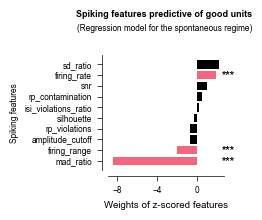

In [7]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig5g", exist_ok=True)
plt.savefig("figures/8_source_data/fig5g/fig5g.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/fig5g/fig5g.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 12.8 ms, sys: 0 ns, total: 12.8 ms
Wall time: 12.8 ms


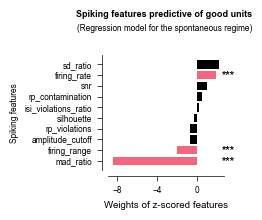

In [8]:
%%time

df = pd.read_excel("figures/8_source_data/fig5g/fig5g.xlsx")
fig, ax = plot_source_data(df)

## Experiment: log-transformed features

* features with a long-tailed distribution (firing rate, firing range, sd ratio, snr, mad ratio) are log-transformed before training and testing the paper's model, on the dataset above (paper Methods: "Log-transforming ... did not improve performance")
* the model is the paper's model, on the dataset above: fractional logistic regression on the 10 quality metrics (raw features), cross-validated as in the paper with 100 random 75% train / 25% test splits
* median and 95% confidence interval of the precision and recall over the splits; nothing is plotted

In [9]:
%%time

# log-transform the features with a long-tailed distribution
dataset_log = dataset.copy()
for feature in ["firing_rate", "firing_range", "sd_ratio", "snr", "mad_ratio"]:
    dataset_log[feature] = np.log(dataset_log[feature].values)
    assert np.isfinite(dataset_log[feature]).all(), f"{feature} log-transform is not finite"  # unit-test

# paper's model: fractional logistic regression on the 10 quality metrics
paper_model = spikecurate.FractionalLogisticClassifier(data["predictors"])

# train & evaluate w/ cross-validation: raw features and log-transformed features
for name, d in [("raw features", dataset), ("log-transformed features", dataset_log)]:
    stats_ = paper_model.crossval_evaluate(d, seeds=model_prms["seeds"], scale_data=model_prms["scale_data"])["metric_stats"]
    print(f"{name}: precision median {stats_['precision_median']:.3f} (95% CI {stats_['precision_ci95']:.3f}), "
          f"recall median {stats_['recall_median']:.3f} (95% CI {stats_['recall_ci95']:.3f})")

raw features: precision median 0.897 (95% CI 0.019), recall median 0.591 (95% CI 0.019)


log-transformed features: precision median 0.913 (95% CI 0.017), recall median 0.632 (95% CI 0.021)
CPU times: user 2.03 s, sys: 0 ns, total: 2.03 s
Wall time: 2.03 s
